In [ ]:
# chat
from langchain_openai import ChatOpenAI

# 모델 생성
llm = ChatOpenAI(model="gpt-4o")
# 대화
llm.invoke("안녕하세요?")   # HumanMessage

AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 10, 'total_tokens': 21, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_4ef908cf62', 'id': 'chatcmpl-Eat66CwMzaDJV3RT113lah6MjOgLZ', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a156f5-b97d-7753-965c-18f4a36206ab-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 11, 'total_tokens': 21, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [ ]:
# 상태 정의(설계)
# 챗봇에 필요한 상태 정의(뭘 저장해야 할지.). 그래프 생성
# 챗봇에 필요한 State class, Node, Edge

# State 정의에 필요 라이브러리 임포트
from typing import Annotated    # 상태 정의 시 사용.
from typing_extensions import TypedDict # dict에 저장될 값(value)의 데이터 타입 지정 시 사용(강제 타입 지정)
from langgraph.graph.message import add_messages    # 메시지 처리 방식 함수(add:추가)

# graph 관련 import
from langgraph.graph import StateGraph, START, END 

In [ ]:
# 챗봇 app => 메시지 저장 => 상태 정의
class State(TypedDict): # 반드시 TypedDict 상속받아야 한다.
    # messages가 key
    # messages=[문자열, 문자열,...]
    # messages:list[str] => 문제 발생 => 덮어 쓰기 => 새로운 값이 기존 값 삭제
    # 추가하는 방식으로 처리: add_messages function
    messages:Annotated[list[str], add_messages]  # 타입 지정. 값과 함수를 묶어주기(Annotated)
                                                 # value에 부가 기능 추가

In [13]:
# 그래프 생성: 노드, 엣지, 상태
# StateGraph 클래스 : State 타입의 그래프 생성.
graph_builder = StateGraph(State)

In [14]:
# 노드 생성
# 노드: 처리하는 함수.
# 대화에서 응답 처리 함수(노드)
def generate(state:State): # 답변 생성. 상태를 받겠다.
    return {"messages":[llm.invoke(state["messages"])]}


In [15]:
graph_builder.add_node("generate", generate)

In [16]:
# 노드(1개)들을 엣지로 연결
graph_builder.add_edge(START,"generate")    # START, "generate" 연결
graph_builder.add_edge("generate",END)  # "generate", END 연결

# graph_builder : 설계도
# 실제 작동하는 그래프 생성
graph = graph_builder.compile()

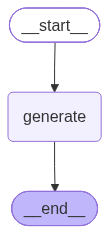

In [18]:
from IPython.display import Image, display


try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass


In [19]:
# 대화 진행
response = graph.invoke({"messages":["안녕하세요. 나는 Yun입니다."]})
print(type(response))
print(response)

<class 'dict'>
{'messages': [HumanMessage(content='안녕하세요. 나는 Yun입니다.', additional_kwargs={}, response_metadata={}, id='dea9df14-89e0-4dfa-8369-73ec7c1eb46e'), AIMessage(content='안녕하세요, Yun님! 만나서 반갑습니다. 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 19, 'prompt_tokens': 14, 'total_tokens': 33, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_bbf31a9d1e', 'id': 'chatcmpl-EauASyzKUoPxTmM6HWXyMlzDBdSH6', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15734-8c83-7f50-a5ce-075d1abc6745-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 

In [20]:
response["messages"].append("내 이름이 뭐지?")
graph.invoke(response)

{'messages': [HumanMessage(content='안녕하세요. 나는 Yun입니다.', additional_kwargs={}, response_metadata={}, id='dea9df14-89e0-4dfa-8369-73ec7c1eb46e'),
  AIMessage(content='안녕하세요, Yun님! 만나서 반갑습니다. 어떻게 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 19, 'prompt_tokens': 14, 'total_tokens': 33, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_bbf31a9d1e', 'id': 'chatcmpl-EauASyzKUoPxTmM6HWXyMlzDBdSH6', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a15734-8c83-7f50-a5ce-075d1abc6745-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_token

In [ ]:
# stream 처리 : 타이핑하는 것처럼 출력
# 질문 저장: State 저장 => State(TypedDict): 딕셔너리 처리해라. 
# messages:list[str] => messages:Annotated[list[str],add_message]
input = {"messages":["한국과 미국의 관계에 대해 자세히 알려줘."]}   # 반드시 이 포멧이어야 함.

# stream_mode:
# messages, values, updates, debug, custom
for chunk, _ in graph.stream(input, stream_mode="messages"):
    print(chunk.content, end="")

한국과 미국의 관계는 1950년대부터 깊은 역사적, 정치적, 경제적, 군사적 연대를 바탕으로 형성되어 왔습니다. 아래는 주요 측면을 정리한 것입니다.

1. **역사적 배경**: 한국과 미국의 관계는 한국전쟁(1950-1953) 이후 본격화되었습니다. 한국전쟁 당시 미국은 유엔군의 일원으로 한국을 지원하였고, 전쟁 이후 한미 상호방위조약을 체결하여 군사적 동맹을 맺었습니다.

2. **군사적 관계**: 한미 상호방위조약을 바탕으로, 미국은 한국에 군사적 지원을 약속하고 있으며, 주한미군이 한국에 주둔하고 있습니다. 이는 북핵 문제 등 한반도의 안보 상황에서 중요한 역할을 하고 있습니다. 양국은 정기적으로 합동 군사훈련을 실시하며, 이를 통해 군사적 협력과 준비태세를 유지하고 있습니다.

3. **경제적 관계**: 대한민국과 미국은 서로 중요한 무역 파트너입니다. 2012년 한미 자유무역협정(FTA)이 발효되면서 양국 간의 무역과 투자가 크게 확대되었습니다. 미국은 한국의 주요 수출국이고, 한국은 미국의 주요 수입국 중 하나입니다.

4. **정치적 관계**: 양국은 민주주의와 인권, 자유시장경제 등을 기반으로 하는 공통 가치를 공유하며, 국제무대에서 협력하고 있습니다. 미국은 한국의 주요 외교적 파트너로, 북한 문제를 포함한 동북아 및 국제 문제에 대해 협력하고 있습니다.

5. **문화적 교류**: 문화적 측면에서도 양국은 활발히 교류하고 있습니다. 한국의 음악, 영화, 음식 등이 미국에서도 인기를 끌고 있으며, 미국의 대중문화도 한국에 큰 영향을 미치고 있습니다. 이러한 문화적 교류는 서로에 대한 이해를 증진시키고 있습니다.

전체적으로 한미 관계는 군사, 경제, 정치, 문화 등 다양한 분야에서 포괄적으로 이루어진 강력한 동맹관계라고 할 수 있습니다. 양국은 서로의 이익을 증진하기 위해 지속적으로 협력하고 있으며, 이러한 관계는 앞으로도 계속해서 발전해 나갈 것으로 보입니다.